In [1]:
import importlib
import numpy as np
import matplotlib.pyplot as plt
import math

from scipy.optimize import root
from scipy.special import expit

import ra_utilities as util #Still ReLu


importlib.reload(util)

<module 'ra_utilities' from '/Users/tinaguo/Desktop/Research/tina_neurocamp/ra_utilities.py'>

In [2]:
import scipy
import sys
import os

print(scipy.__version__)
print(sys.executable)
print(os.getpid())

1.18.0
/Users/tinaguo/miniforge3/envs/neuro/bin/python
57654


In [3]:
# def relu(h):
#     return np.maximum(h, 0.0)


# def relu_prime(h):
#     """Derivative of relu."""
#     return (np.asarray(h) > 0.0).astype(float)


def softplus(h, beta=1.0):
    """Smooth approximation to ReLU."""
    h = np.asarray(h)
    return np.logaddexp(0.0, beta * h) / beta


def softplus_prime(h, beta=1.0):
    """Derivative of softplus."""
    return expit(beta * np.asarray(h))
# #def sigmoid？

# # Plot to show the comparison between softplus and ReLU
# x = np.linspace(-4, 4, 500)

# plt.figure(figsize=(7, 4))
# plt.plot(x, relu(x), label="ReLU", lw=2)

# for beta in [0.5, 1.0, 2.0, 3.0, 4.0, 5.0]:
#     plt.plot(
#         x,
#         softplus(x, beta=beta),
#         label=fr"Softplus $\beta={beta}$"
#     )
# # beta value 1.0 or 2.0 would provide better approximation
# plt.xlabel(r"$h$")
# plt.ylabel(r"$\phi(h)$")
# plt.legend()
# plt.show()

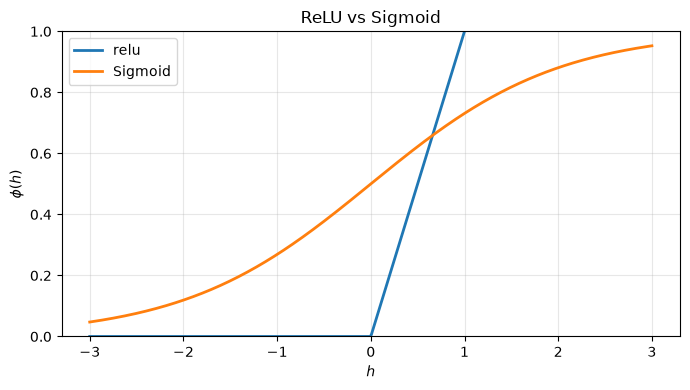

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def relu(h):
    """ReLU activation function."""
    return np.maximum(h, 0.0)


def relu_prime(h):
    """Derivative of ReLU."""
    return (np.asarray(h) > 0.0).astype(float)


def sigmoid(h):
    """Sigmoid activation function."""
    h = np.asarray(h)
    return 1 / (1 + np.exp(-h))


def sigmoid_prime(h):
    """Derivative of sigmoid."""
    s = sigmoid(h)
    return s * (1 - s)


# Plot comparison between sigmoid and ReLU
x = np.linspace(-3, 3, 500)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(x, relu(x), label="relu", lw=2)
ax.plot(x, sigmoid(x), label="Sigmoid", lw=2)

ax.set_xlabel(r"$h$")
ax.set_ylabel(r"$\phi(h)$")
ax.set_title("ReLU vs Sigmoid")
ax.legend()
ax.grid(True, alpha=0.3)

plt.ylim(0, 1)
plt.tight_layout()
plt.show()

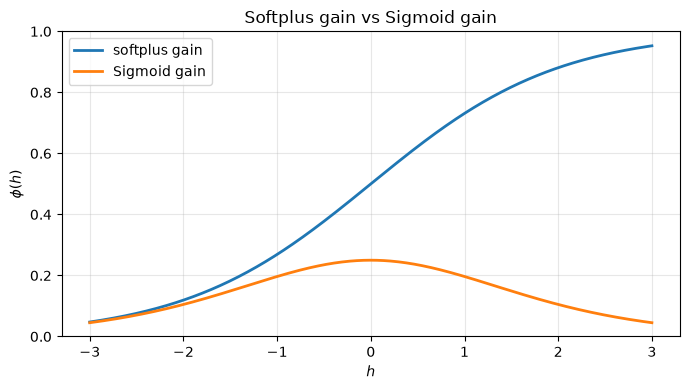

In [5]:
x = np.linspace(-3, 3, 500)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(x, softplus_prime(x), label="softplus gain", lw=2)
ax.plot(x, sigmoid_prime(x), label="Sigmoid gain", lw=2)

ax.set_xlabel(r"$h$")
ax.set_ylabel(r"$\phi(h)$")
ax.set_title("Softplus gain vs Sigmoid gain")
ax.legend()
ax.grid(True, alpha=0.3)

plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [6]:
# Comparison : ReLU results from article:
N =6
Nact = N #Settle for now(Will change the value for JI)
# Concept of active neurons only applies to ReLU 

theta = util.preferred_headings(N)

cff = 1.0
tau = 0.1


psi_preferred = theta[0]# All simulations start from preferred heading 0, could change to other values for phase drift scan
psi_midpoint = 0.5 * (theta[0] + theta[1])

JE_relu = util.optimal_JE(N, Nact)
JI_relu = util.find_JI_for_amplitude(
    N,
    JE_relu,
    cff=cff,
    target_amplitude=0.2,
)

print("ReLU JE* =", JE_relu)
print("ReLU JI  =", JI_relu)

ReLU JE* = 2.0
ReLU JI  = -9.005682373046874


In [7]:

print(util.preferred_headings(N))

[0.         1.04719755 2.0943951  3.14159265 4.1887902  5.23598776]


In [8]:
def rate_and_gain_projections(
    H0, a, psi, theta, phi, dphi
):
    """Compute the R and Q quantities of the reduced system.These are parameters to 
    simplify the matrix equation and fixed point calculation later on"""

    delta = theta - psi
    cos_delta = np.cos(delta)
    sin_delta = np.sin(delta)

    # h_k = H0 + a cos(theta_k - psi)
    h = H0 + a * cos_delta

    # Firing rate and local nonlinear gain
    r = phi(h)
    gain = dphi(h)

    # Rate projections
    R0 = np.mean(r)
    Rc = np.mean(r * cos_delta)
    Rs = np.mean(r * sin_delta)

    # Gain-weighted moments/projections
    Q0 = np.mean(gain)
    Q1 = np.mean(gain * cos_delta)
    Q2 = np.mean(gain * cos_delta**2)
    Qs = np.mean(gain * sin_delta**2)

    return {
        "h": h,
        "r": r,
        "gain": gain,
        "R0": R0,
        "Rc": Rc,
        "Rs": Rs,
        "Q0": Q0,
        "Q1": Q1,
        "Q2": Q2,
        "Qs": Qs,
    }

In [9]:
#A test run: Assign softplus under phi definition,assign random H0 and a)
phi = lambda h: sigmoid(h)
dphi = lambda h: sigmoid_prime(h)
# Define R and Q params to simplify Equations and Jacobian computation later.
q = rate_and_gain_projections(
    H0=-0.5,
    a=1.0,
    psi=psi_preferred,
    theta=theta,
    phi=phi,
    dphi=dphi,
)

for name in ["R0", "Rc", "Rs", "Q0", "Q1", "Q2", "Qs"]:
    print(name, q[name])

print("Q0 - (Q2 + Qs) =", q["Q0"] - q["Q2"] - q["Qs"])
#check Q0 - (Q2 + Qs)=0; Rs = 0(approx): 

R0 0.39046128295803345
Rc 0.11184873100425057
Rs 1.850371707708594e-17
Q0 0.21289567179248184
Q1 0.023207554481629977
Q2 0.10124268848211139
Qs 0.11165298331037045
Q0 - (Q2 + Qs) = 0.0


Given (JI,JE,phi)：

0= -H0+ JI* R0+ cff

0= −a+ JE* Rc
	​


In [10]:
def fixed_point_residual(
    x, JI, JE, cff, psi, theta, phi, dphi
):
    H0, a = x

    q = rate_and_gain_projections(
        H0, a, psi, theta, phi, dphi
    )

    F0 = -H0 + JI * q["R0"] + cff
    Fa = -a + JE * q["Rc"]
    
    return np.array([F0, Fa])

In [11]:
# Gain initial guess??? Still use ReLU params for initial softplus computation
def extract_reduced_coordinates(h, theta):
    """Extract H0, a, psi from a network input profile h."""
    h = np.asarray(h)
#Fourier computation
    H0 = np.mean(h)
    H1 = np.mean(h * np.exp(-1j * theta))

    a = 2.0 * np.abs(H1)
    psi = (-np.angle(H1)) % (2.0 * np.pi)

    return H0, a, psi

phi = lambda h: sigmoid(h)
dphi = lambda h: sigmoid_prime(h)

h_final = util.simulate_bump(
    N=N,
    JE=JE_relu,#Use RelU 
    JI=JI_relu,
    cff=cff,
    vin=0.0,
    tau=tau,
    t_max=10.0,
    dt=0.01,
    psi0=psi_preferred,
    phi=phi,
    return_trajectory=False,
    animate=False,JE_noise=None, JI_noise=None, method="RK45"
)

#simulate_bump(N, JE, JI, cff=1.0, vin=0.0, tau=0.1, t_max=3.0, dt=0.01,
#                    psi0=0.0, h0=None, phi=threshold_linear,
#                    return_trajectory=True, animate=False,
#                    JE_noise=None, JI_noise=None, method="RK45")

H0_guess, a_guess,psi = extract_reduced_coordinates(
     h_final, theta)
#In this case psi shouldn't be a valid orientation 
print("initial guess:")
print("H0 guess =", H0_guess)
print("a guess =", a_guess)

#print(h_final)

# Relu parameter doesn't transfer directly to softplus, homogeneous fixed point result

initial guess:
H0 guess = -1.1562671494459165
a guess = 2.220446049250313e-16


In [12]:
#scipy.optimize.root solve
solution = root(fixed_point_residual,
    #x0=np.array([H0_guess, a_guess]),#starting from homgeneous branch
    x0=np.array([-1.0, 1.0]),#starting from other spot
    args=(
        JI_relu,
        JE_relu,
        cff,
        psi_preferred,
        theta,
        phi,
        dphi,
    ),
)

#Check test
print("success:", solution.success)# convergence success
print("message:", solution.message)#standard:"The solution converged"
print("residual:", solution.fun)# input results back to function, should be approx 0

H0_star, a_star= solution.x
q_check = rate_and_gain_projections(
    H0_star, a_star, psi_preferred,
    theta, phi, dphi
)

print("R0 =", q_check["R0"])
print("F0 =", -H0_star + JI_relu * q_check["R0"] + cff)


print("H0* =", H0_star)
print("a*  =", a_star)

# a star is approx zero, not a bump fixed point solution,homogeneuos fixed point

success: True
message: The solution converged.
residual: [ 6.79833967e-12 -1.72442759e-14]
R0 = 0.23940078925516592
F0 = 6.7983396689896836e-12
H0* = -1.1559674678955554
a*  = 2.1065293441073022e-14


In [13]:
# dhdt_final = util.network_rhs(
#     10.0,
#     h_final,
#     N,
#     JE_relu,
#     JI_relu,
#     cff,
#     0.0,          # vin
#     tau,
#     phi,
#     None,         # JE_noise
#     None          # JI_noise
# )

# print(dhdt_final)


In [14]:
# Calculate eigenvalues of the Jacobian
def reduced_eigenvalues(
    H0, a, psi, JI, JE, theta, phi, dphi, tau=1.0
):
    q = rate_and_gain_projections(
        H0, a, psi, theta, phi, dphi
    )

    Q0 = q["Q0"]
    Q1 = q["Q1"]
    Q2 = q["Q2"]
    Qs = q["Qs"]

    A = np.array([
        [-1.0 + JI * Q0, JI * Q1],
        [JE * Q1, -1.0 + JE * Q2],
    ])

    lambda_pm_dimensionless = np.linalg.eigvals(A)
    lambda_psi_dimensionless = -1.0 + JE * Qs

    return {
        "A": A,
        "lambda_pm": lambda_pm_dimensionless / tau,
        "lambda_psi": lambda_psi_dimensionless / tau,
        "quantities": q,
    }# Note:return a dictionary, use key to extract
# Use calculated eigenvalues from the dictionary(name:stability)
stability = reduced_eigenvalues(
    H0=H0_star,
    a=a_star,
    psi=psi_preferred,
    JI=JI_relu,
    JE=JE_relu,
    theta=theta,
    phi=phi,
    dphi=dphi,
    tau=tau,
)

print("A =")
print(stability["A"])

print("lambda_pm =", stability["lambda_pm"])
print("lambda_psi =", stability["lambda_psi"])

A =
[[-2.63982715e+00 -8.95682468e-15]
 [ 1.98914959e-15 -8.17911949e-01]]
lambda_pm = [-26.39827154+0.j  -8.17911949+0.j]
lambda_psi = -8.179119486408304


In [15]:
# #Check if reduced eigenvalues is the same as the elements from full jacobian eigenvalue sets
# def full_network_jacobian(
#     h_star, N, JE, JI, tau, dphi
# ):
#     W = util.symmetric_weights(N, JE, JI)
#     gain = dphi(h_star)

#     J = (
#         -np.eye(N)
#         + W * gain[None, :] / N#gain[None,:]--shape=(1, N)
#     ) / tau

#     return J

# q_star = stability["quantities"]
# h_star = q_star["h"]

# J_full = full_network_jacobian(
#     h_star=h_star,
#     N=N,
#     JE=JE_relu,
#     JI=JI_relu,
#     tau=tau,
#     dphi=dphi,
# )

# eig_full = np.linalg.eigvals(J_full)
# eig_full = eig_full[np.argsort(eig_full.real)[::-1]]# sort from max to min

# print("largest full-network eigenvalues:")
# print(eig_full[:])

# print("H0_star =", H0_star)
# print("a_star  =", a_star)

# q = stability["quantities"]
# #Printing these values out also comfirmed that we found homogeneous fixed points(h min=h max)
# print("h range =", q["h"].min(), q["h"].max())
# print("r range =", q["r"].min(), q["r"].max())

# print("R0 =", q["R0"])
# print("Rc =", q["Rc"])
# print("Rs =", q["Rs"])

# print("Q0 =", q["Q0"])
# print("Q1 =", q["Q1"])
# print("Q2 =", q["Q2"])
# print("Qs =", q["Qs"])

In [16]:
#This shows using JE JI value from ReLU result only found  homogeneous fixed points instead of a bump fixed point
#Using the analysis framework, we now solve for JE and JI value in other nonlinear function cases, need to rewrite functions to calculate JE
#along with selected JI values

In [17]:
def rate_and_gain_projections(
    H0, a, psi, theta, phi, dphi
):
    """Compute the R and Q quantities of the reduced system.These are parameters to 
    simplify the matrix equation and fixed point calculation later on"""

    delta = theta - psi
    cos_delta = np.cos(delta)
    sin_delta = np.sin(delta)

    # h_k = H0 + a cos(theta_k - psi)
    h = H0 + a * cos_delta

    # Firing rate and local nonlinear gain
    r = phi(h)
    gain = dphi(h)

    # Rate projections
    R0 = np.mean(r)
    Rc = np.mean(r * cos_delta)
    Rs = np.mean(r * sin_delta)

    # Gain-weighted moments/projections
    Q0 = np.mean(gain)
    Q1 = np.mean(gain * cos_delta)
    Q2 = np.mean(gain * cos_delta**2)
    Qs = np.mean(gain * sin_delta**2)

    return {
        "h": h,
        "r": r,
        "gain": gain,
        "R0": R0,
        "Rc": Rc,
        "Rs": Rs,
        "Q0": Q0,
        "Q1": Q1,
        "Q2": Q2,
        "Qs": Qs,
    }

In [18]:
phi = lambda h: sigmoid(h)
dphi = lambda h: sigmoid_prime(h)

def fixed_point_new(
    x, JI, cff, psi, theta, phi, dphi
):
    H0, log_a, JE = x
    a = np.exp(log_a)#to keep a>0 for reasonable bump configuration
    
    q = rate_and_gain_projections(
        H0, a, psi, theta, phi, dphi
    )

    F0 = -H0 + JI * q["R0"] + cff
    Fa = -a + JE * q["Rc"]
    FE = -1 + JE * q["Qs"]
    
    return np.array([F0, Fa,FE])


In [19]:
# phi = lambda h: sigmoid(h)
# dphi = lambda h: sigmoid_prime(h)

# def fixed_point_new(x, JE, JI, cff, psi, theta, phi, dphi):

#     H0, log_a = x
#     a = np.exp(log_a)  # Keep a > 0

#     q = rate_and_gain_projections(
#         H0, a, psi, theta, phi, dphi
#     )

#     F0 = -H0 + JI*q["R0"] + cff
#     Fa = -1 + JE*q["Rc"]/a

#     return np.array([F0, Fa])


In [20]:

# Given JI, solve for H0, a, JE
# satisfying F0 = Fa = FE = 0 at preferred orientation

JI_ini = -6.0
JE_guess = 10.0
psi_preferred = 0.0

solution = root(
    fixed_point_new,
    x0=[-0.8, np.log(1.0), JE_guess],
    args=(
        JI_ini, cff,
        psi_preferred, theta, phi, dphi
    )
)

H0_ini = solution.x[0]
a_ini = np.exp(solution.x[1])
JE_ini = solution.x[2]

q_check = rate_and_gain_projections(
    H0_ini, a_ini, psi_preferred,
    theta, phi, dphi
)

print("Success =", solution.success)
print("Residual norm =", np.linalg.norm(solution.fun))

print("R0 =", q_check["R0"])
print("F0 =", -H0_ini + JI_ini * q_check["R0"] + cff)
print("Fa =", -a_ini + JE_ini * q_check["Rc"])
print("Rs =", q_check["Rs"])
print("FE =", -1 + JE_ini * q_check["Qs"])

print("H0* =", H0_ini)
print("a*  =", a_ini)
print("A*  =", H0_ini + a_ini)
print("JE* =", JE_ini)
print("JI* =", JI_ini)

if not solution.success or np.linalg.norm(solution.fun) > 1e-8:
    print("WARNING: Valid marginal fixed point not confirmed.")


Success = True
Residual norm = 8.282330733990694e-14
R0 = 0.31550102182658707
F0 = -6.461498003318411e-14
Fa = -4.707345624410664e-14
Rs = 4.625929269271486e-17
FE = -2.1649348980190553e-14
H0* = -0.8930061309594579
a*  = 1.1395156745646378
A*  = 0.24650954360517985
JE* = 10.094241790870932
JI* = -6.0


In [21]:
#Check residual vector for the solution
print("Residual norm =", np.linalg.norm(solution.fun))
print("Max residual =", np.max(np.abs(solution.fun)))

Residual norm = 8.282330733990694e-14
Max residual = 6.461498003318411e-14


In [22]:
# # # pass the solved JE value back to bump simulation and see the validity of solution
# t,h_final = util.simulate_bump(
#     N=N,
#     JE=JE_ini, 
#     JI=JI_ini,
#     cff=cff,
#     vin=1.0,
#     tau=tau,
#     t_max=10.0,
#     dt=0.01,
#     psi0= 0,#psi_preferred
#     phi=phi,
#     return_trajectory=True,
#     animate=True,JE_noise=None, JI_noise=None, method="RK45"
# )


# H0_guess, a_guess,psi = extract_reduced_coordinates(
#      h_final, theta)
# #In this case psi shouldn't be a valid orientation 
# print("initial guess:")
# print("H0 guess =", H0_guess)
# print("a guess =", a_guess)
# print("JE =",JE_ini)
# print("JI=",JI_ini)
# print("psi_start", psi0)
# print("theta=",psi)


In [23]:
print("N =", N)
print("len(theta) =", len(theta))
print("theta =", theta)

print("JI_ini =", JI_ini)
print("JE_ini =", JE_ini)


N = 6
len(theta) = 6
theta = [0.         1.04719755 2.0943951  3.14159265 4.1887902  5.23598776]
JI_ini = -6.0
JE_ini = 10.094241790870932


In [24]:
# JI_magnitude=abs(JI_test)
# JI_values = -np.linspace(0.5*JI_magnitude,2*JI_magnitude,16)

# def find_target_JE(JI_test,H0_ini,a_ini):
#     solution = root(fixed_point_new,
#     x0=np.array([H0_ini, a_ini, JE_ini]),
#     args=(
#         JI_test,
#         cff,
#         psi_preferred,
#         theta,
#         phi,
#         dphi,
#     ))
    
#     H0_star, a_star, JE_star = solution.x
#     psi_star = psi_preferred

#     residual = np.linalg.norm(solution.fun)

#     if not (
#         np.all(np.isfinite(solution.x))
#         and np.isfinite(residual)
#         and JE_star > 0
#     ):
#         return np.nan, np.nan, np.nan

#     return JE_star,a_star,H0_star


# JE_values=[]
# a_values=[]
# H0_values=[]
# for JI in JI_values:
#     JE_star,a_star,H0_star=find_target_JE(JI,H0_ini,a_ini)
#     JE_values.append(JE_star)
#     a_values.append(a_star)
#     H0_values.append(H0_star)
# JE_values = np.array(JE_values)
# a_values=np.array(a_values)
# H0_values=np.array(H0_values)



# print("JI values:", JI_values)
# print("JE values:", JE_values)
# print("a values:", a_values)
# print("H0 values:", H0_values)


In [60]:

# Scan JE; solve F0 = Fa = FE = 0
# No fixed A constraint

JE_values = np.linspace(8.5, 14.0, 16)

def find_target_JI(JE_test, previous=None):

    def equations(x):
        H0, log_a = x

        if not np.all(np.isfinite(x)) or not (-20 < log_a < 5):
            return np.array([1e4, 1e4])

        a = np.exp(log_a)

        q = rate_and_gain_projections(
            H0, a, psi_preferred,
            theta, phi, dphi
        )

        Fa_scaled = -1 + JE_test * q["Rc"] / a
        FE = -1 + JE_test * q["Qs"]

        return np.array([Fa_scaled, FE])

    guesses = []

    if previous is not None:
        guesses.append(previous)

    # Broader starting guesses
    for H0_guess in [-0.8, -1.5, -3.0, -5.0, -6.0]:
        for a_guess in [1.0, 2.0, 4.0, 8.0, 16.0]:
            guesses.append([H0_guess, np.log(a_guess)])

    for x0 in guesses:

        solution = root(
            equations,
            x0=x0,
            options={"maxfev": 1000}
        )

        if not solution.success:
            continue

        H0_star, log_a_star = solution.x

        if not (np.log(0.3) < log_a_star < np.log(50)):
            continue

        a_star = np.exp(log_a_star)

        q = rate_and_gain_projections(
            H0_star, a_star, psi_preferred,
            theta, phi, dphi
        )

        # F0 = 0 determines JI
        JI_star = (H0_star - cff) / q["R0"]

        # Verify all three original equations
        residuals = np.array([
            -H0_star + JI_star * q["R0"] + cff,
            -a_star + JE_test * q["Rc"],
            -1 + JE_test * q["Qs"]
        ])

        contrast = phi(H0_star + a_star) - phi(H0_star - a_star)

        if (
            np.all(np.isfinite(residuals))
            and np.linalg.norm(residuals) < 1e-8
            and JI_star < 0
            and contrast > 0.1
        ):
            return JI_star, a_star, H0_star

    return np.nan, np.nan, np.nan


JI_values = []
a_values = []
H0_values = []

previous = None

for JE in JE_values:

    JI_star, a_star, H0_star = find_target_JI(
        JE, previous=previous
    )

    JI_values.append(JI_star)
    a_values.append(a_star)
    H0_values.append(H0_star)

    if np.all(np.isfinite([JI_star, a_star, H0_star])):
        previous = [H0_star, np.log(a_star)]

JI_values = np.array(JI_values)
a_values = np.array(a_values)
H0_values = np.array(H0_values)

print("JE values:", JE_values)
print("JI values:", JI_values)
print("a values:", a_values)
print("H0 values:", H0_values)
print("A values:", H0_values + a_values)

print("Valid solutions:", np.isfinite(JI_values).sum())


/var/folders/k0/5ryg5t_53dxfkcx8vnyq56h40000gn/T/ipykernel_57654/3009137957.py:17: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-h))


JE values: [ 8.5         8.86666667  9.23333333  9.6         9.96666667 10.33333333
 10.7        11.06666667 11.43333333 11.8        12.16666667 12.53333333
 12.9        13.26666667 13.63333333 14.        ]
JI values: [        nan         nan         nan -6.09822558 -6.02141863 -5.96606293
 -5.92742984 -5.90210428 -5.88756475 -5.88191404 -5.88370121 -5.89180068
 -5.90532809 -5.92358067 -5.94599413 -5.97211097]
a values: [       nan        nan        nan 0.45122641 1.00603514 1.35734819
 1.64161769 1.88946158 2.1138243  2.32160273 2.51697578 2.70269487
 2.88068039 3.05233208 3.21870484 3.38061513]
H0 values: [        nan         nan         nan -0.85072202 -0.88213207 -0.91332751
 -0.94438542 -0.97537201 -1.00634448 -1.03735243 -1.06843907 -1.09964211
 -1.13099454 -1.16252526 -1.19425955 -1.22621954]
A values: [        nan         nan         nan -0.39949561  0.12390306  0.44402068
  0.69723227  0.91408957  1.10747983  1.2842503   1.44853672  1.60305276
  1.74968585  1.88980682  2.02444

In [26]:
# # # pass the solved JE value back to bump simulation and see the validity of solution
# JE_simu=50
# JI_simu=-14.074
# t,h_final = util.simulate_bump(
#     N=N,
#     JE=JE_simu, 
#     JI=JI_simu,
#     cff=cff,
#     vin=10.0,
#     tau=tau,
#     t_max=10.0,
#     dt=0.01,
#     psi0= 1,#psi_preferred
#     phi=phi,
#     return_trajectory=True,
#     animate=True,JE_noise=None, JI_noise=None, method="RK45"
# )

# #simulate_bump(N, JE, JI, cff=1.0, vin=0.0, tau=0.1, t_max=3.0, dt=0.01,
# #                    psi0=0.0, h0=None, phi=threshold_linear,
# #                    return_trajectory=True, animate=False,
# #                    JE_noise=None, JI_noise=None, method="RK45")

# H0_guess, a_guess,psi = extract_reduced_coordinates(
#      h_final, theta)
# #In this case psi shouldn't be a valid orientation 
# print("initial guess:")
# print("H0 guess =", H0_guess)
# print("a guess =", a_guess)# Always bigger than 0 because of the extract_reduced_coordinates function construction
# print("JE =",JE_simu)
# print("JI=",JI_simu)
# print("psi_start", psi0)
# print("theta=",psi)

In [27]:
# for JE, JI in zip(JE_values, JI_values):

#     if not np.isfinite(JI):
#         continue

#     print(f"JE = {JE:.3f}, JI = {JI:.3f}")

#     t, h = util.simulate_bump(
#         N=N,
#         JE=JE,
#         JI=JI,
#         cff=cff,
#         vin=10.0,
#         tau=tau,
#         t_max=10.0,
#         dt=0.01,
#         psi0=0.0,
#         phi=phi,
#         return_trajectory=True,
#         animate=True,
#         JE_noise=None,
#         JI_noise=None,
#         method="BDF"
#     )


    

In [61]:
import pandas as pd
results = []

for i in range(len(JE_values)):

    JE = JE_values[i]
    JI = JI_values[i]
    a = a_values[i]
    H0 = H0_values[i]

    if not np.all(np.isfinite([JE, JI, a, H0])):
        continue

    q = rate_and_gain_projections(
        H0, a, psi_preferred, theta, phi, dphi
    )

    F0 = -H0 + JI*q["R0"] + cff
    Fa = -a + JE*q["Rc"]
    FE = -1 + JE*q["Qs"]

    results.append({
        "JE": JE,
        "JI": JI,
        "H0": H0,
        "a": a,
        "A": H0 + a,
        "F0": F0,
        "Fa": Fa,
        "Rs": q["Rs"],
        "FE": FE
    })

df = pd.DataFrame(results)
display(df)

,JE,JI,H0,a,A,F0,Fa,Rs,FE
0,9.600000,-6.098226,-0.850722,0.451226,-0.399496,0.000000e+00,1.831868e-15,2.775558e-17,3.774758e-15
1,9.966667,-6.021419,-0.882132,1.006035,0.123903,0.000000e+00,-1.576517e-14,2.775558e-17,-1.820766e-14
2,10.333333,-5.966063,-0.913328,1.357348,0.444021,0.000000e+00,2.109424e-14,1.850372e-17,2.220446e-14
3,10.700000,-5.927430,-0.944385,1.641618,0.697232,3.330669e-16,8.437695e-15,3.700743e-17,6.661338e-15
4,11.066667,-5.902104,-0.975372,1.889462,0.914090,2.220446e-16,1.412204e-13,1.850372e-17,1.094680e-13
5,11.433333,-5.887565,-1.006344,2.113824,1.107480,0.000000e+00,1.110223e-14,2.775558e-17,8.437695e-15
6,11.800000,-5.881914,-1.037352,2.321603,1.284250,0.000000e+00,-2.470912e-12,2.775558e-17,-1.868616e-12
7,12.166667,-5.883701,-1.068439,2.516976,1.448537,2.220446e-16,-3.219647e-13,1.850372e-17,-2.413625e-13
8,12.533333,-5.891801,-1.099642,2.702695,1.603053,-2.220446e-16,-4.440892e-14,1.850372e-17,-3.286260e-14
9,12.900000,-5.905328,-1.130995,2.880680,1.749686,0.000000e+00,7.564172e-12,2.775558e-17,5.566658e-12


In [62]:

# Midpoint Fixed Point Validation
# Keep JE, JI fixed; solve H0, a again at psi = pi/N

results_mid = []

for i in range(len(JE_values)):

    JE = JE_values[i]
    JI = JI_values[i]
    H0_pref = H0_values[i]
    a_pref = a_values[i]

    if not np.all(np.isfinite([JE, JI, H0_pref, a_pref])):
        continue

    # Solve midpoint fixed-point equations: F0 = Fa = 0
    def midpoint_equations(x):

        H0, log_a = x
        a = np.exp(log_a)

        q = rate_and_gain_projections(
            H0, a, psi_midpoint, theta, phi, dphi
        )

        F0 = -H0 + JI * q["R0"] + cff
        Fa = -a + JE * q["Rc"]

        return np.array([F0, Fa])

    solution = root(
        midpoint_equations,
        x0=[H0_pref, np.log(a_pref)]
    )

    H0_mid = solution.x[0]
    a_mid = np.exp(solution.x[1])

    q = rate_and_gain_projections(
        H0_mid, a_mid, psi_midpoint,
        theta, phi, dphi
    )

    F0 = -H0_mid + JI*q["R0"] + cff
    Fa = -a_mid + JE*q["Rc"]
    Rs = q["Rs"]
    FE = -1 + JE*q["Qs"]

    residual = np.linalg.norm([F0, Fa, JE*Rs])

    valid = (
        solution.success
        and np.all(np.isfinite([H0_mid, a_mid, residual]))
        and residual < 1e-8
        and a_mid > 0.1
    )

    results_mid.append({
        "JE": JE,
        "JI": JI,
        "H0_mid": H0_mid if valid else np.nan,
        "a_mid": a_mid if valid else np.nan,
        "A_mid": H0_mid + a_mid if valid else np.nan,
        "F0": F0 if valid else np.nan,
        "Fa": Fa if valid else np.nan,
        "Rs": Rs if valid else np.nan,
        "FE": FE if valid else np.nan,
        "valid": valid
    })

df_mid = pd.DataFrame(results_mid)
display(df_mid.round(6))

#Notice the FE value for midpoint stability


,JE,JI,H0_mid,a_mid,A_mid,F0,Fa,Rs,FE,valid
0,9.600000,-6.098226,-0.850721,0.451228,-0.399493,-0.0,0.0,0.0,0.000000,True
1,9.966667,-6.021419,-0.882063,1.006097,0.124035,0.0,0.0,0.0,0.000000,True
2,10.333333,-5.966063,-0.912943,1.357544,0.444601,0.0,-0.0,0.0,0.000004,True
3,10.700000,-5.927430,-0.943281,1.641941,0.698660,-0.0,0.0,0.0,0.000019,True
4,11.066667,-5.902104,-0.973014,1.889799,0.916785,-0.0,0.0,0.0,0.000064,True
5,11.433333,-5.887565,-1.002103,2.113950,1.111847,-0.0,0.0,0.0,0.000158,True
6,11.800000,-5.881914,-1.030526,2.321182,1.290656,0.0,-0.0,0.0,0.000325,True
7,12.166667,-5.883701,-1.058278,2.515577,1.457299,0.0,-0.0,0.0,0.000588,True
8,12.533333,-5.891801,-1.085370,2.699805,1.614435,0.0,-0.0,0.0,0.000968,True
9,12.900000,-5.905328,-1.111823,2.875721,1.763898,0.0,-0.0,0.0,0.001479,True


In [30]:
# Fixed point Validation Baseline:

#1. Pass the solved h_star back into the dynamical equation and see if residual approx= 0

#2. Jacobian local linear stability analysis- Eigenvalue

#3. Amplitude Scan: Near the same orientation psi,set the initial bump amplitude to different
#values, will it return to the stationary bump solution as suggested by fixed-point equations?

#4. Phase drift : (Notes on the finite-size phase pinning effect)


In [63]:
# 1. Dynamical Equation check:
# for preferred orientation
N = len(theta)

full_residuals = []

for i in range(len(JI_values)):

    JI_star = JI_values[i]
    JE_star = JE_values[i]
    H0_star = H0_values[i]
    a_star = a_values[i]

    if not np.all(np.isfinite([
        JI_star, JE_star, H0_star, a_star
    ])):
        full_residuals.append(np.nan)
        continue

    #Reconstruct neuron input activity:
    h_star = (
        H0_star
        + a_star * np.cos(theta - psi_preferred)
    )

    dhdt = util.network_rhs(
        t=0.0,
        h=h_star,
        N=N,
        JE=JE_star,
        JI=JI_star,
        cff=cff,
        vin=0.0,
        tau=tau,
        phi=phi
    )

    # Calculate full fixed-point residual
    residual_vector = tau * dhdt

    full_residual = np.max(np.abs(residual_vector))
    full_residuals.append(full_residual)

    print(
        f"i={i:2d} | "
        f"JI={JI_star:.4f} | "
        f"JE={JE_star:.4f} | "
        f"a={a_star:.6f} | "
        f"H0={H0_star:.6f} | "
        f"Full residual={full_residual:.3e}"
    )

full_residuals = np.array(full_residuals)

i= 3 | JI=-6.0982 | JE=9.6000 | a=0.451226 | H0=-0.850722 | Full residual=2.220e-15
i= 4 | JI=-6.0214 | JE=9.9667 | a=1.006035 | H0=-0.882132 | Full residual=1.621e-14
i= 5 | JI=-5.9661 | JE=10.3333 | a=1.357348 | H0=-0.913328 | Full residual=2.176e-14
i= 6 | JI=-5.9274 | JE=10.7000 | a=1.641618 | H0=-0.944385 | Full residual=8.882e-15
i= 7 | JI=-5.9021 | JE=11.0667 | a=1.889462 | H0=-0.975372 | Full residual=1.411e-13
i= 8 | JI=-5.8876 | JE=11.4333 | a=2.113824 | H0=-1.006344 | Full residual=1.066e-14
i= 9 | JI=-5.8819 | JE=11.8000 | a=2.321603 | H0=-1.037352 | Full residual=2.472e-12
i=10 | JI=-5.8837 | JE=12.1667 | a=2.516976 | H0=-1.068439 | Full residual=3.215e-13
i=11 | JI=-5.8918 | JE=12.5333 | a=2.702695 | H0=-1.099642 | Full residual=4.441e-14
i=12 | JI=-5.9053 | JE=12.9000 | a=2.880680 | H0=-1.130995 | Full residual=7.566e-12
i=13 | JI=-5.9236 | JE=13.2667 | a=3.052332 | H0=-1.162525 | Full residual=1.074e-12
i=14 | JI=-5.9460 | JE=13.6333 | a=3.218705 | H0=-1.194260 | Full r

In [64]:

# 2. Local Stability Analysis: Dynamical Jacobian
import numpy as np

N = len(theta)

lambda_plus_values = []
lambda_minus_values = []
lambda_psi_values = []

J_reduced_values = []
J_full_values = []

for i in range(len(JI_values)):

    JI = JI_values[i]
    JE = JE_values[i]
    H0 = H0_values[i]
    a = a_values[i]

    # Skip invalid solutions
    if not np.all(np.isfinite([JI, JE, H0, a])):
        lambda_plus_values.append(np.nan)
        lambda_minus_values.append(np.nan)
        lambda_psi_values.append(np.nan)
        J_reduced_values.append(None)
        J_full_values.append(None)
        continue

    if full_residuals[i] > 1e-6:
        lambda_plus_values.append(np.nan)
        lambda_minus_values.append(np.nan)
        lambda_psi_values.append(np.nan)
        J_reduced_values.append(None)
        J_full_values.append(None)
        continue

    q = rate_and_gain_projections(
        H0, a, psi_preferred,
        theta, phi, dphi
    )

    Q0 = q["Q0"]
    Q1 = q["Q1"]
    Q2 = q["Q2"]
    Qs = q["Qs"]
    Rc = q["Rc"]

    h_star = q["h"]
    gain = q["gain"]

    W = JI + JE * np.cos(
        theta[:, None] - theta[None, :]
    )
# Compute directly from dynamical equation:
    J_full = (
        -np.eye(N) + W * gain[None, :] / N
    ) / tau

    eig_full = np.linalg.eigvals(J_full)

    J_full_values.append(J_full)

#Reduced dynamical Jacobian (3 x 3) at fixed point:
    if abs(a) < 1e-6:
        lambda_plus_values.append(np.nan)
        lambda_minus_values.append(np.nan)
        lambda_psi_values.append(np.nan)
        J_reduced_values.append(None)

        print(f"i={i}: near homogeneous; use full Jacobian")
        continue

    J_reduced = np.array([
        [-1 + JI*Q0,  JI*Q1,       0],
        [JE*Q1,      -1 + JE*Q2,  0],
        [0,          0,           JE*Qs - JE*Rc/a]
    ]) / tau

    J_reduced_values.append(J_reduced)

#Eigenvalues (H0, a) First two rows
    A = J_reduced[:2, :2]

    eig_trans = np.linalg.eigvals(A)

    eig_trans = eig_trans[
        np.argsort(eig_trans.real)[::-1]
    ]

    lambda_plus = eig_trans[0]
    lambda_minus = eig_trans[1]

    #Phase eigenvalue: lambda_psi：
    lambda_psi = J_reduced[2, 2]

    # Equivalent at an exact stationary bump：#Use the fixed point condition Fa=0
    lambda_psi_FE = (-1 + JE*Qs) / tau


    lambda_plus_values.append(lambda_plus)
    lambda_minus_values.append(lambda_minus)
    lambda_psi_values.append(lambda_psi)

    print(f"\ni = {i}, JI = {JI:.4f}, JE = {JE:.4f}")
    print(f"a = {a:.6f}")

    print(f"lambda_plus  = {lambda_plus:.8g}")
    print(f"lambda_minus = {lambda_minus:.8g}")
    print(f"lambda_psi   = {lambda_psi:.8g}")

    print(f"lambda_psi (FE) = {lambda_psi_FE:.8g}")
    print(f"Full residual   = {full_residuals[i]:.3e}")


lambda_plus_values = np.array(lambda_plus_values)
lambda_minus_values = np.array(lambda_minus_values)
lambda_psi_values = np.array(lambda_psi_values)


i = 3, JI = -6.0982, JE = 9.6000
a = 0.451226
lambda_plus  = -0.21966034+0j
lambda_minus = -22.533249+0j
lambda_psi   = -2.220446e-15
lambda_psi (FE) = 3.7747583e-14
Full residual   = 2.220e-15

i = 4, JI = -6.0214, JE = 9.9667
a = 1.006035
lambda_plus  = -1.009085+0j
lambda_minus = -21.324693+0j
lambda_psi   = -2.553513e-14
lambda_psi (FE) = -1.8207658e-13
Full residual   = 1.621e-14

i = 5, JI = -5.9661, JE = 10.3333
a = 1.357348
lambda_plus  = -1.7054257+0j
lambda_minus = -20.309102+0j
lambda_psi   = 6.6613381e-14
lambda_psi (FE) = 2.220446e-13
Full residual   = 2.176e-14

i = 6, JI = -5.9274, JE = 10.7000
a = 1.641618
lambda_plus  = -2.3250056+0j
lambda_minus = -19.44453+0j
lambda_psi   = 1.5543122e-14
lambda_psi (FE) = 6.6613381e-14
Full residual   = 8.882e-15

i = 7, JI = -5.9021, JE = 11.0667
a = 1.889462
lambda_plus  = -2.8801613+0j
lambda_minus = -18.700071+0j
lambda_psi   = 3.4638958e-13
lambda_psi (FE) = 1.0946799e-12
Full residual   = 1.411e-13

i = 8, JI = -5.8876, JE = 1

In [65]:

# 2‘. Midpoint Local Stability Analysis: Dynamical Jacobian

import numpy as np

N = len(theta)

lambda_plus_mid_values = []
lambda_minus_mid_values = []
lambda_psi_mid_values = []

J_reduced_mid_values = []
J_full_mid_values = []

full_residuals_mid = []

for i, row in enumerate(df_mid.itertuples(index=False)):

    JE = row.JE
    JI = row.JI
    H0 = row.H0_mid
    a = row.a_mid

    # Skip invalid midpoint solutions
    if (
        not row.valid
        or not np.all(np.isfinite([JE, JI, H0, a]))
        or a < 1e-6
    ):
        lambda_plus_mid_values.append(np.nan)
        lambda_minus_mid_values.append(np.nan)
        lambda_psi_mid_values.append(np.nan)
        J_reduced_mid_values.append(None)
        J_full_mid_values.append(None)
        full_residuals_mid.append(np.nan)
        continue

    q = rate_and_gain_projections(
        H0, a, psi_midpoint,
        theta, phi, dphi
    )

    Q0 = q["Q0"]
    Q1 = q["Q1"]
    Q2 = q["Q2"]
    Qs = q["Qs"]
    Rc = q["Rc"]

    h_star = q["h"]
    gain = q["gain"]

    W = JI + JE * np.cos(
        theta[:, None] - theta[None, :]
    )

    # 1. Validate fixed point in the full network equation
    full_rhs = (
        -h_star + cff + W @ q["r"] / N
    )

    full_residual = np.linalg.norm(full_rhs)
    full_residuals_mid.append(full_residual)

    if full_residual > 1e-6:
        lambda_plus_mid_values.append(np.nan)
        lambda_minus_mid_values.append(np.nan)
        lambda_psi_mid_values.append(np.nan)
        J_reduced_mid_values.append(None)
        J_full_mid_values.append(None)
        continue

    # 2. Full N x N dynamical Jacobian
    J_full = (
        -np.eye(N) + W * gain[None, :] / N
    ) / tau

    eig_full = np.linalg.eigvals(J_full)
    J_full_mid_values.append(J_full)

    # 3. Reduced 3 x 3 Jacobian at midpoint
    J_reduced = np.array([
        [-1 + JI*Q0,  JI*Q1,       0],
        [JE*Q1,      -1 + JE*Q2,  0],
        [0,          0,           JE*Qs - JE*Rc/a]
    ]) / tau

    J_reduced_mid_values.append(J_reduced)

    # Amplitude eigenvalues
    A = J_reduced[:2, :2]

    eig_trans = np.linalg.eigvals(A)
    eig_trans = eig_trans[
        np.argsort(eig_trans.real)[::-1]
    ]

    lambda_plus = eig_trans[0]
    lambda_minus = eig_trans[1]

    # Phase eigenvalue
    lambda_psi = J_reduced[2, 2]

    # Equivalent at stationary bump (Fa = 0)
    lambda_psi_FE = (-1 + JE*Qs) / tau

    lambda_plus_mid_values.append(lambda_plus)
    lambda_minus_mid_values.append(lambda_minus)
    lambda_psi_mid_values.append(lambda_psi)

    print(f"\ni = {i}, JI = {JI:.4f}, JE = {JE:.4f}")
    print(f"H0_mid = {H0:.6f}, a_mid = {a:.6f}")

    print(f"lambda_plus  = {lambda_plus:.8g}")
    print(f"lambda_minus = {lambda_minus:.8g}")
    print(f"lambda_psi   = {lambda_psi:.8g}")

    print(f"lambda_psi (FE) = {lambda_psi_FE:.8g}")
    print(f"Full residual   = {full_residual:.3e}")

# Save midpoint results
lambda_plus_mid_values = np.array(lambda_plus_mid_values)
lambda_minus_mid_values = np.array(lambda_minus_mid_values)
lambda_psi_mid_values = np.array(lambda_psi_mid_values)
full_residuals_mid = np.array(full_residuals_mid)

# Summary table aligned with df_mid
df_mid_stability = df_mid.copy()

df_mid_stability["lambda_plus"] = lambda_plus_mid_values
df_mid_stability["lambda_minus"] = lambda_minus_mid_values
df_mid_stability["lambda_psi"] = lambda_psi_mid_values
df_mid_stability["full_residual"] = full_residuals_mid

df_mid_stability["amplitude_stable"] = (
    (lambda_plus_mid_values.real < 0)
    & (lambda_minus_mid_values.real < 0)
)

df_mid_stability["phase_stable"] = (
    lambda_psi_mid_values < -1e-8
)

display(df_mid_stability.round(6))



i = 0, JI = -6.0982, JE = 9.6000
H0_mid = -0.850721, a_mid = 0.451228
lambda_plus  = -0.21965277+0j
lambda_minus = -22.533265+0j
lambda_psi   = 9.1254559e-10
lambda_psi (FE) = 9.1255004e-10
Full residual   = 1.923e-15

i = 1, JI = -6.0214, JE = 9.9667
H0_mid = -0.882063, a_mid = 1.006097
lambda_plus  = -1.0083681+0j
lambda_minus = -21.326402+0j
lambda_psi   = 2.2267484e-06
lambda_psi (FE) = 2.2267484e-06
Full residual   = 8.647e-14

i = 2, JI = -5.9661, JE = 10.3333
H0_mid = -0.912943, a_mid = 1.357544
lambda_plus  = -1.7020786+0j
lambda_minus = -20.317905+0j
lambda_psi   = 3.5832733e-05
lambda_psi (FE) = 3.5832733e-05
Full residual   = 6.753e-16

i = 3, JI = -5.9274, JE = 10.7000
H0_mid = -0.943281, a_mid = 1.641941
lambda_plus  = -2.3168757+0j
lambda_minus = -19.468087+0j
lambda_psi   = 0.0001933427
lambda_psi (FE) = 0.0001933427
Full residual   = 1.410e-13

i = 4, JI = -5.9021, JE = 11.0667
H0_mid = -0.973014, a_mid = 1.889799
lambda_plus  = -2.8654633+0j
lambda_minus = -18.746981+

,JE,JI,H0_mid,a_mid,A_mid,F0,Fa,Rs,FE,valid,lambda_plus,lambda_minus,lambda_psi,full_residual,amplitude_stable,phase_stable
0,9.600000,-6.098226,-0.850721,0.451228,-0.399493,-0.0,0.0,0.0,0.000000,True,-0.219653+0.000000j,-22.533265+ 0.000000j,0.000000,0.0,True,False
1,9.966667,-6.021419,-0.882063,1.006097,0.124035,0.0,0.0,0.0,0.000000,True,-1.008368+0.000000j,-21.326402+ 0.000000j,0.000002,0.0,True,False
2,10.333333,-5.966063,-0.912943,1.357544,0.444601,0.0,-0.0,0.0,0.000004,True,-1.702079+0.000000j,-20.317905+ 0.000000j,0.000036,0.0,True,False
3,10.700000,-5.927430,-0.943281,1.641941,0.698660,-0.0,0.0,0.0,0.000019,True,-2.316876+0.000000j,-19.468087+ 0.000000j,0.000193,0.0,True,False
4,11.066667,-5.902104,-0.973014,1.889799,0.916785,-0.0,0.0,0.0,0.000064,True,-2.865463+0.000000j,-18.746981+ 0.000000j,0.000636,0.0,True,False
5,11.433333,-5.887565,-1.002103,2.113950,1.111847,-0.0,0.0,0.0,0.000158,True,-3.358034+0.000000j,-18.131419+ 0.000000j,0.001576,0.0,True,False
6,11.800000,-5.881914,-1.030526,2.321182,1.290656,0.0,-0.0,0.0,0.000325,True,-3.802862+0.000000j,-17.603146+ 0.000000j,0.003248,0.0,True,False
7,12.166667,-5.883701,-1.058278,2.515577,1.457299,0.0,-0.0,0.0,0.000588,True,-4.206717+0.000000j,-17.147551+ 0.000000j,0.005882,0.0,True,False
8,12.533333,-5.891801,-1.085370,2.699805,1.614435,0.0,-0.0,0.0,0.000968,True,-4.575171+0.000000j,-16.752799+ 0.000000j,0.009678,0.0,True,False
9,12.900000,-5.905328,-1.111823,2.875721,1.763898,0.0,-0.0,0.0,0.001479,True,-4.912831+0.000000j,-16.409215+ 0.000000j,0.014792,0.0,True,False


H0 and a - Mixed Eigenmodes: Relaxation Time Analysis?

In [ ]:
# # 3. Amplitude Scan
# def preferred_headings(N):
#     """Evenly spaced preferred headings theta_j for a ring of N neurons.

#     Args:
#         N: number of neurons (computational units) in the ring.

#     Returns:
#         Array of shape (N,) of preferred headings in [0, 2*pi).
#     """
#     return np.arange(N) * 2 * np.pi / N

# def init_bump(N, psi0, width=None, amplitude=1.0):
#     """Initialize a cosine-shaped bump of activity centered at psi0.

#     Args:
#         N: number of neurons.
#         psi0: initial bump orientation (rad).
#         width: unused placeholder kept for interface symmetry with the
#             paper's (a, w, psi) bump parametrization; the single-ring model
#             here uses a raw cosine bump instead.
#         amplitude: peak activity of the initial bump.

#     Returns:
#         Array of shape (N,) giving initial input activity h_0.
#     """
#     theta = preferred_headings(N)
#     return amplitude * np.cos(theta - psi0)

# for i in range(len(JI_values)):

#     N = len(theta)
#     JI_fixed = JI_values[i]
#     JE_fixed = JE_values[i]

#     psi0 = psi_preferred
#     H0_start = H0_values[i]

#     a_initial_values = [0.01, 0.1, 0.5, 1.0, 2.0]
    

#     for a_init in a_initial_values:

#         # Initialize bump with a chosen amplitude
#         h0 = H0_start + init_bump(
#             N, psi0, amplitude=a_init
#         )

#         # Simulate the SAME network
#         t, h = util.simulate_bump(
#             N=N,
#             JE=JE_fixed,
#             JI=JI_fixed,
#             cff=cff,
#             vin=0.0,
#             tau=tau,
#             t_max=5000* tau,
#             dt=tau,
#             h0=h0,
#             phi=phi,          # Use your sigmoid!
#             animate=False,
#             method="BDF"
#         )

#         h_final = h[-1]

#     #simulate_bump(N, JE, JI, cff=1.0, vin=0.0, tau=0.1, t_max=3.0, dt=0.01,
#     #                    psi0=0.0, h0=None, phi=threshold_linear,
#     #                    return_trajectory=True, animate=False,
#     #                    JE_noise=None, JI_noise=None, method="RK45")

#         H0_now, a_now,psi = extract_reduced_coordinates(
#             h_final, theta)
#         print(  f"i = {i:.4f}  -->  "
#                 f"JE={JE_fixed:.4f} "
#                 f"JI={JI_fixed:.4f}, "
#                 f"a_init = {a_init:.4f}  -->  "
#                 f"a_final = {a_now:.6f}, "
#                 f"H0_final = {H0_now:.6f}, "
#                 f"psi_final = {psi:.6f}"
#             )

The sensitivity toward initial condition for cases in N=8/N=6: could be slow convergence,could test by extending the time for the simulation;  Finite-time sensitivity to initial conditions; t_max=5000* tau： results:N=8 converge,N=6:a =0.00x,Is it homogenoues solution? 


Interesting phenomenon:
As N gets smaller, if a_init value gets closer to zero- failed to generate bump solution, instead generate a approx=0; Also could be approaching homogeneous branch, all the a_final values are significantly smaller than 1?

Critical JE value for homogenoues solution calculation, homogeneous brach analysis? Why N affect?

Target not reached within simulation time.
Do not interpret this as exactly zero drift.


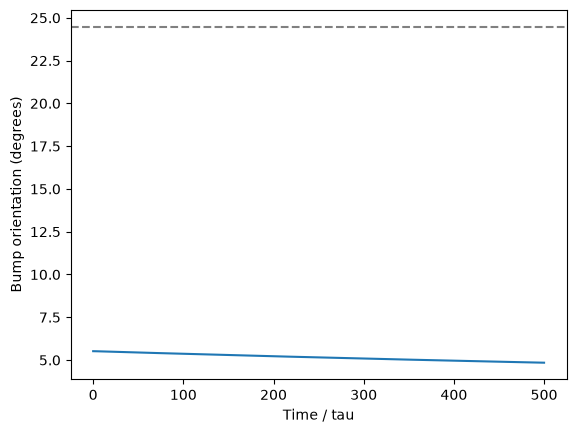

In [67]:

# 4. Net Drift Speed Analysis

i = 15

JE_fixed = JE_values[i]
JI_fixed = JI_values[i]
H0_fixed = H0_values[i]
a_fixed = a_values[i]

delta = np.pi / N
eps = delta / (2 * np.e)

# Determine the direction of phase drift
# at a point between 0 and pi/N.
q_mid = rate_and_gain_projections(
    H0_fixed, a_fixed, delta/2,
    theta, phi, dphi
)

omega_mid = JE_fixed * q_mid["Rs"] / (tau * a_fixed)

if abs(omega_mid) < 1e-12:
    print("Phase force is very small; direction uncertain.")
else:
    direction = np.sign(omega_mid)

    if direction < 0:
        # 0 stable, pi/N unstable
        psi_init = delta - eps
        psi_target = eps
    else:
        # pi/N stable, 0 unstable
        psi_init = eps
        psi_target = delta - eps

    h0 = H0_fixed + a_fixed * np.cos(
        theta - psi_init
    )

    t, h = util.simulate_bump(
        N=N,
        JE=JE_fixed,
        JI=JI_fixed,
        cff=cff,
        vin=0.0,
        tau=tau,
        t_max=500*tau,
        dt=tau,
        h0=h0,
        phi=phi,
        return_trajectory=True,
        animate=False,
        method="BDF"
    )

    # Extract phase from the first Fourier mode
    z = (2/N) * (h @ np.exp(1j*theta))
    a_trace = np.abs(z)
    psi_trace = np.unwrap(np.angle(z))

    # Keep the orientation on the initial angular branch
    psi_trace += 2*np.pi * np.round(
        (psi_init - psi_trace[0]) / (2*np.pi)
    )

    # Find first passage to the target
    crossed = np.where(
        direction * (psi_trace - psi_target) >= 0
    )[0]

    if np.min(a_trace) < 1e-4:
        print("Warning: bump amplitude became too small.")

    if len(crossed) > 0 and crossed[0] > 0:
        k = crossed[0]

        # Interpolate passage time
        fraction = (
            (psi_target - psi_trace[k-1])
            / (psi_trace[k] - psi_trace[k-1])
        )

        t_pass = (
            t[k-1]
            + fraction * (t[k] - t[k-1])
            - t[0]
        )

        delta_psi = delta - 2*eps
        drift_speed = delta_psi / t_pass

        print("Passage time =", t_pass)
        print("Drift speed (rad/s) =", drift_speed)
        print("Drift speed (deg/s) =",
              np.degrees(drift_speed))
    else:
        drift_speed = np.nan
        print("Target not reached within simulation time.")
        print("Do not interpret this as exactly zero drift.")

    plt.plot(t/tau, np.degrees(psi_trace))
    plt.axhline(np.degrees(psi_target),
                linestyle="--", color="gray")
    plt.xlabel("Time / tau")
    plt.ylabel("Bump orientation (degrees)")
    plt.show()


In [ ]:

# 4. Phase Drift Analysis
# Preferred-marginality branch: vin = 0

psi0_list = np.linspace(0, np.pi/N, 21)
psi0_deg_list = np.rad2deg(psi0_list)

def angular_error(psi_final, psi_initial):
    return np.abs(
        np.angle(np.exp(1j * (psi_final - psi_initial)))
    )

T_MAX = 50.0
DT = 0.02

drift_results = []

valid_indices = [
    i for i in range(len(JE_values))
    if np.all(np.isfinite([
        JE_values[i], JI_values[i],
        H0_values[i], a_values[i]
    ]))
    and np.real(lambda_plus_values[i]) < 0
    and np.real(lambda_minus_values[i]) < 0
]

ncols = 3
nrows = int(np.ceil(len(valid_indices) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(15, 3 * nrows),
    squeeze=False
)

axes = axes.flatten()

for k, i in enumerate(valid_indices):

    JE = JE_values[i]
    JI = JI_values[i]
    H0 = H0_values[i]
    a = a_values[i]

    ax = axes[k]

    for psi0_deg, psi0 in zip(psi0_deg_list, psi0_list):

        # Rotate the solved preferred bump
        # to a non-preferred initial orientation
        h0 = H0 + a * np.cos(theta - psi0)

        t, h = util.simulate_bump(
            N=N,
            JE=JE,
            JI=JI,
            cff=cff,
            vin=0.0,
            tau=tau,
            t_max=T_MAX,
            dt=DT,
            h0=h0,
            phi=phi,
            return_trajectory=True,
            animate=False,
            method="BDF"
        )

        if (
            len(t) < 2
            or t[-1] < T_MAX - 1e-6
            or not np.all(np.isfinite(h))
        ):
            print(f"Simulation incomplete: JE={JE:.3f}, "
                  f"psi0={psi0_deg} deg")
            continue

        # Extract the first Fourier mode of input activity
        z = (2.0 / N) * (
            h @ np.exp(1j * theta)
        )

        a_trace = np.abs(z)
        psi_trace = np.unwrap(np.angle(z))

        # Phase is undefined if the bump disappears
        if np.min(a_trace) < 1e-3:
            print(f"Bump amplitude too small: JE={JE:.3f}")
            continue

        psi_deg = np.rad2deg(psi_trace)

        ax.plot(
            t, psi_deg,
            label=f"{psi0_deg}°"
        )

        # Final orientation
        psi_final = psi_trace[-1]

        # Fold orientation into the fundamental sector [0, pi/N]
        period = 2 * np.pi / N
        psi_mod = psi_final % period
        psi_fold = min(psi_mod, period - psi_mod)
        phase_error_deg = np.rad2deg(angular_error(psi_final, psi0))
                                                   
        drift_results.append({
            "JE": JE,
            "JI": JI,
            "psi0_deg": psi0_deg,
            "psi_final_deg": np.degrees(psi_final),
            "psi_final_fold_deg": np.degrees(psi_fold),
            "drift_deg": np.degrees(
                psi_final - psi_trace[0]
            ),
            "phase_error_deg": phase_error_deg,
            "a_final": a_trace[-1]
        })

    ax.axhline(
        0, color="gray",
        linestyle="--", alpha=0.4
    )

    ax.axhline(
        180 / N, color="red",
        linestyle="--", alpha=0.4
    )

    ax.set_title(f"JE={JE:.2f}, JI={JI:.2f}")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Bump orientation (deg)")
    ax.grid(alpha=0.2)

    if k == 0:
        ax.legend(title="Initial psi", fontsize=8)

# Hide empty panels
for ax in axes[len(valid_indices):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

df_drift = pd.DataFrame(drift_results)
display(df_drift.round(4))


In [84]:

# Step 1. Solve stationary bump at fixed JE and JI
# Only solve F0 = Fa = 0
# Do NOT impose FE = 0 or fixed amplitude

def solve_bump_fixed_connectivity(
    JE,
    JI,
    seed_H0,
    seed_a,
    psi=psi_preferred,
    residual_tol=1e-7,
    a_min=0.1,
    contrast_min=0.1,
    stability_tol=1e-8
):

    # Use log(a) to ensure positive amplitude
    def equations_logamp(x):

        H0, log_a = x

        if (
            not np.all(np.isfinite(x))
            or not (-20 < log_a < 20)
        ):
            return np.array([1e6, 1e6])

        a = np.exp(log_a)

        return fixed_point_residual(
            [H0, a],
            JI,
            JE,
            cff,
            psi,
            theta,
            phi,
            dphi
        )

    # Initial guess from the marginal reference bump
    solution = root(
        equations_logamp,
        x0=[seed_H0, np.log(seed_a)],
        options={"maxfev": 2000}
    )

    H0, log_a = solution.x
    a = np.exp(log_a)

    if not np.all(np.isfinite([H0, a])) or abs(log_a) >= 20:
        return {
            "JE": JE, "JI": JI,
            "H0": np.nan, "a": np.nan,
            "A": np.nan,
            "fp_residual": np.inf,
            "full_residual": np.inf,
            "rate_contrast": np.nan,
            "valid": False
        }

    # Recalculate the fixed-point quantities
    q = rate_and_gain_projections(
        H0, a, psi,
        theta, phi, dphi
    )

    F0, Fa = fixed_point_residual(
        [H0, a],
        JI,
        JE,
        cff,
        psi,
        theta,
        phi,
        dphi
    )

    fp_residual = np.linalg.norm([F0, Fa])

    # --------------------------------------------------
    # Verify against the full N-neuron dynamical equation
    # Use the existing util.network_rhs
    # --------------------------------------------------

    h_star = H0 + a * np.cos(theta - psi)

    dhdt = util.network_rhs(
        t=0.0,
        h=h_star,
        N=N,
        JE=JE,
        JI=JI,
        cff=cff,
        vin=0.0,
        tau=tau,
        phi=phi
    )

    full_residual = np.max(
        np.abs(tau * dhdt)
    )

    # Actual firing-rate contrast across neurons
    rate_contrast = np.ptp(q["r"])

    # --------------------------------------------------
    # Reduced Jacobian eigenvalues
    # Reuse the existing reduced_eigenvalues function
    # --------------------------------------------------

    stability = reduced_eigenvalues(
        H0=H0,
        a=a,
        psi=psi,
        JI=JI,
        JE=JE,
        theta=theta,
        phi=phi,
        dphi=dphi,
        tau=tau
    )

    eig_pm = np.asarray(stability["lambda_pm"])

    eig_pm = eig_pm[
        np.argsort(eig_pm.real)[::-1]
    ]

    lambda_plus = eig_pm[0].real
    lambda_minus = eig_pm[1].real

    lambda_psi = np.real(
        stability["lambda_psi"]
    )

    # --------------------------------------------------
    # Full N x N Jacobian
    # Follow the construction in your original cell 32
    # --------------------------------------------------

    W = JI + JE * np.cos(
        theta[:, None] - theta[None, :]
    )

    J_full = (
        -np.eye(N) + W * q["gain"][None, :] / N
    ) / tau

    eig_full = np.linalg.eigvals(J_full)

    transverse_stable = (
        lambda_plus < -stability_tol
        and lambda_minus < -stability_tol
    )

    phase_stable = (
        lambda_psi < -stability_tol
    )

    full_stable = np.all(
        eig_full.real < -stability_tol
    )

    # --------------------------------------------------
    # Final validity check
    # --------------------------------------------------

    valid = (
        np.all(np.isfinite([
            H0, a, fp_residual,
            full_residual, rate_contrast
        ]))
        and fp_residual < residual_tol
        and full_residual < residual_tol
        and a > a_min
        and rate_contrast > contrast_min
    )

    return {
        "JE": JE,
        "JI": JI,
        "H0": H0,
        "a": a,
        "A": H0 + a,

        "F0": F0,
        "Fa": Fa,

        "fp_residual": fp_residual,
        "full_residual": full_residual,
        "rate_contrast": rate_contrast,

        "lambda_plus": lambda_plus,
        "lambda_minus": lambda_minus,
        "lambda_psi": lambda_psi,

        "transverse_stable": transverse_stable,
        "phase_stable": phase_stable,
        "full_stable": full_stable,

        "solver_success": solution.success,
        "valid": valid
    }


In [ ]:

# Step 2. Two-dimensional connectivity perturbation

# Select the reference point from the preferred-marginality branch
i_star = 1

JE_star = JE_values[i_star]
JI_star = JI_values[i_star]
H0_star = H0_values[i_star]
a_star = a_values[i_star]

print("Reference parameters:")
print(f"JE* = {JE_star:.6f}")
print(f"JI* = {JI_star:.6f}")
print(f"H0* = {H0_star:.6f}")
print(f"a*  = {a_star:.6f}")

# Relative perturbation grid
eta_E_values = np.linspace(-0.20, 0.20, 9)
eta_I_values = np.linspace(-0.20, 0.20, 9)

scan_results = []

for eta_I in eta_I_values:

    for eta_E in eta_E_values:

        JE = JE_star * (1 + eta_E)

        JI = (
            JI_star
            + abs(JI_star) * eta_I
        )

        row = solve_bump_fixed_connectivity(
            JE=JE,
            JI=JI,
            seed_H0=H0_star,
            seed_a=a_star
        )

        row["eta_E"] = eta_E
        row["eta_I"] = eta_I

        scan_results.append(row)

df_scan = pd.DataFrame(scan_results)

display(
    df_scan[[
        "eta_E", "eta_I",
        "JE", "JI",
        "H0", "a", "A",
        "fp_residual",
        "full_residual",
        "rate_contrast",
        "lambda_plus",
        "lambda_minus",
        "lambda_psi",
        "transverse_stable",
        "phase_stable",
        "full_stable",
        "valid"
    ]].round(6)
)


In [ ]:
# # pass the solved JE value back to bump simulation and see the validity of solution
JE_simu=9.6
JI_simu=-4
t,h_final = util.simulate_bump(
    N=N,
    JE=JE_simu, 
    JI=JI_simu,
    cff=cff,
    vin=0.0,
    tau=tau,
    t_max=20.0,
    dt=0.01,
    h0=-2+2.014226* np.cos(theta - 0.2617),#psi_preferred
    phi=phi,
    return_trajectory=True,
    animate=True,JE_noise=0, JI_noise=0, method="RK45"
)

#simulate_bump(N, JE, JI, cff=1.0, vin=0.0, tau=0.1, t_max=3.0, dt=0.01,
#                    psi0=0.0, h0=None, phi=threshold_linear,
#                    return_trajectory=True, animate=False,
#                    JE_noise=None, JI_noise=None, method="RK45")

H0_guess, a_guess,psi = extract_reduced_coordinates(
     h_final, theta)
#In this case psi shouldn't be a valid orientation 
print("initial guess:")
print("H0 guess =", H0_guess)
print("a guess =", a_guess)# Always bigger than 0 because of the extract_reduced_coordinates function construction
print("JE =",JE_simu)
print("JI=",JI_simu)
print("theta=",psi)

Animation size has reached 20987080 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


initial guess:
H0 guess = 4.919462627117461
a guess = 0.03756829589545109
JE = 9.6
JI= -4
theta= 0.2610668410675781


In [ ]:
theta = util.preferred_headings(N)
midpoints = (theta + np.pi/N) % (2*np.pi)

print(f"N = {N}")
print("Neuron-centered orientations (deg):")
print(np.round(np.degrees(theta), 4))

print("\nMidpoint orientations (deg):")
print(np.round(np.degrees(midpoints), 4))

print("\nAll symmetric phase candidates (deg):")
all_phases = np.sort(np.concatenate([theta, midpoints]))
print(np.round(np.degrees(all_phases), 4))


N = 6
Neuron-centered orientations (deg):
[  0.  60. 120. 180. 240. 300.]

Midpoint orientations (deg):
[ 30.  90. 150. 210. 270. 330.]

All symmetric phase candidates (deg):
[  0.  30.  60.  90. 120. 150. 180. 210. 240. 270. 300. 330.]


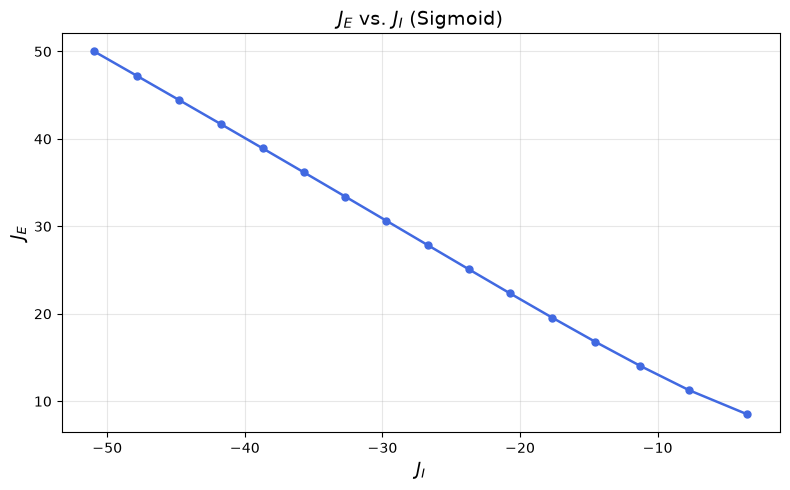

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))

plt.plot(
    JI_values,
    JE_values,
    'o-',
    color='royalblue',
    linewidth=1.8,
    markersize=5
)

plt.xlabel(r'$J_I$', fontsize=13)
plt.ylabel(r'$J_E$', fontsize=13)
plt.title(r'$J_E$ vs. $J_I$ (Sigmoid)', fontsize=14)

plt.grid(True, alpha=0.3)
plt.tight_layout()

# plt.savefig(
#     "figures/JE_vs_JI_N16_Sigmoid.png",
#     dpi=300,
#     bbox_inches="tight"
# )
plt.show()

In [ ]:
# np.savez(
#     "data/coupling_scan_N16_Sigmoid.npz",
#     JI=JI_values,
#     JE=JE_values,
#     amplitude=a_values,
#     H0=H0_values,
#     N=N,
#     cff=cff,
#     tau=tau
# )

In [ ]:
# for JI, JE in zip(JI_values, JE_values):

#     if not np.isfinite(JE):
#         continue

#     print(f"Simulating JI={JI:.3f}, JE={JE:.3f}")

#     t, h = util.simulate_bump(
#         N=N,
#         JE=JE,
#         JI=JI,
#         cff=cff,
#         vin=1.0,
#         tau=tau,
#         t_max=10.0,
#         dt=0.01,
#         psi0=psi_preferred,
#         phi=phi,
#         return_trajectory=True,
#         animate=True,
#         JE_noise=None,
#         JI_noise=None,
#         method="RK45"
#     )
#     h_final = h[-1]

#     H0_final, a_final, psi_final = (
#         extract_reduced_coordinates(h_final, theta)
#     )

#     print(f"JI = {JI:.3f}, JE = {JE:.3f}")
#     print(f"Final amplitude = {a_final:.6f}")
#     print(f"Final orientation = {psi_final:.6f}")
#     print("-" * 40)